# Load the data and get the sampling parameters

Uniform sampling: True
N  = 601
Ts = 0.005 s   ->   fs = 200.0 Hz
Record length = 3.005 s   ->   Δf = fs/N = 0.3328 Hz
Nyquist = 100.0 Hz


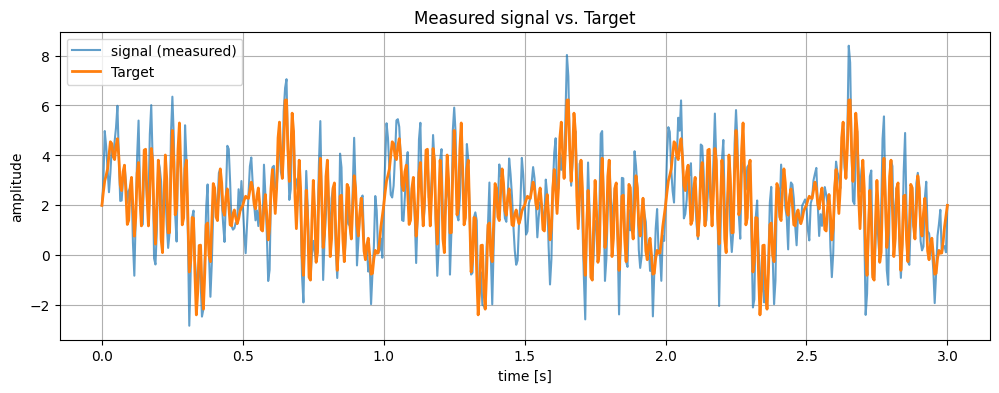

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the data (only Sheet1 has data; column D is empty, so skip it)
df = pd.read_excel("Filter_Design_Assignment_DATA.xlsx", sheet_name="Sheet1",
                   usecols=["index", "time", "signal", "Target"])

n      = df["index"].to_numpy()
t      = df["time"].to_numpy()
x      = df["signal"].to_numpy()    # measured (noisy) signal
target = df["Target"].to_numpy()    # clean reference

# Sampling parameters
N  = len(x)
Ts = t[1] - t[0]
fs = 1 / Ts

# Check that the sampling is uniform (an assumption of the DFT)
print("Uniform sampling:", np.allclose(np.diff(t), Ts))
print(f"N  = {N}")
print(f"Ts = {Ts} s   ->   fs = {fs:.1f} Hz")
print(f"Record length = {N*Ts:.3f} s   ->   Δf = fs/N = {fs/N:.4f} Hz")
print(f"Nyquist = {fs/2:.1f} Hz")

# Quick look at the signal vs. the target
plt.figure(figsize=(12, 4))
plt.plot(t, x, label="signal (measured)", alpha=0.7)
plt.plot(t, target, label="Target", linewidth=2)
plt.xlabel("time [s]"); plt.ylabel("amplitude")
plt.legend(); plt.grid(True); plt.title("Measured signal vs. Target")
plt.show()

# DFT of the target and signal

Matches np.fft.fft: True


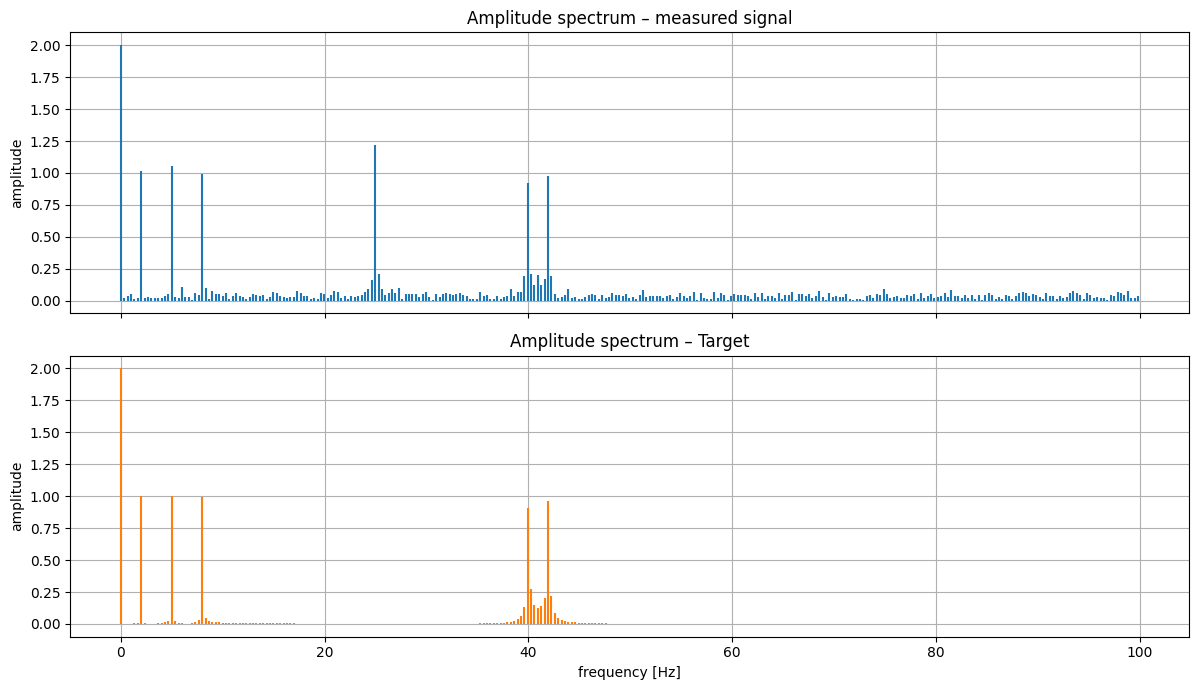

k =   0   f =   0.00 Hz   amplitude = 2.002
k =   6   f =   2.00 Hz   amplitude = 1.019
k =  15   f =   4.99 Hz   amplitude = 1.055
k =  24   f =   7.99 Hz   amplitude = 0.992
k =  75   f =  24.96 Hz   amplitude = 1.219
k =  76   f =  25.29 Hz   amplitude = 0.208
k = 120   f =  39.93 Hz   amplitude = 0.921
k = 121   f =  40.27 Hz   amplitude = 0.205
k = 123   f =  40.93 Hz   amplitude = 0.204
k = 126   f =  41.93 Hz   amplitude = 0.977


In [2]:
# --- DFT straight from the definition: X[k] = sum_n x[n] e^{-j 2π k n / N} ---
k  = np.arange(N).reshape(-1, 1)        # bin index (column)
nn = np.arange(N).reshape(1, -1)        # sample index (row)
W  = np.exp(-2j * np.pi * k * nn / N)   # N x N matrix: row k = basis sinusoid k

X = W @ x          # each X[k] = inner product of the whole signal with basis k
T = W @ target

print("Matches np.fft.fft:", np.allclose(X, np.fft.fft(x)))

# --- Single-sided amplitude spectrum (real signal -> keep k = 0 ... N//2) ---
half = N // 2 + 1
f    = np.arange(half) * fs / N          # bin k  ->  k * fs/N  Hz

def amp_spectrum(Z):
    A = np.abs(Z[:half]) / N             # scale by N
    A[1:] *= 2                           # fold in the negative-frequency half (not DC)
    return A

Ax = amp_spectrum(X)
At = amp_spectrum(T)

# --- Plot ---
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].stem(f, Ax, markerfmt=" ", basefmt=" ")
ax[0].set_title("Amplitude spectrum – measured signal")
ax[1].stem(f, At, markerfmt=" ", basefmt=" ", linefmt="C1-")
ax[1].set_title("Amplitude spectrum – Target")
for a in ax:
    a.set_ylabel("amplitude"); a.grid(True)
ax[1].set_xlabel("frequency [Hz]")
plt.tight_layout(); plt.show()

# --- List the dominant peaks ---
peaks = np.argsort(Ax)[::-1][:10]
for i in sorted(peaks):
    print(f"k = {i:3d}   f = {f[i]:6.2f} Hz   amplitude = {Ax[i]:.3f}")

# Filter Design

Noise peak: k = 75,  f0 = 24.96 Hz
theta0 = 0.7854 rad = 45.0°
zeros: [0.7071+0.7071j 0.7071-0.7071j]
poles: [0.6364+0.6364j 0.6364-0.6364j]


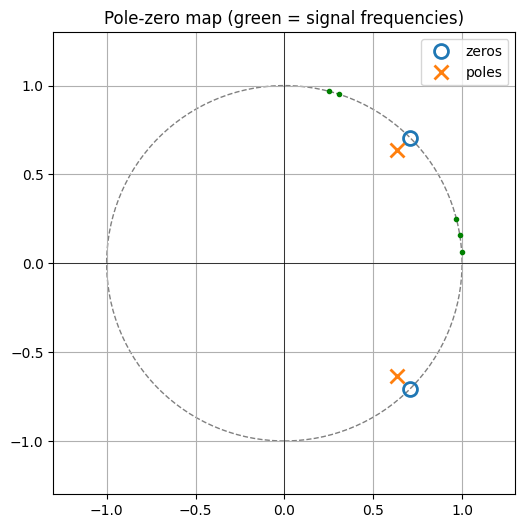

In [3]:
# --- 1. Locate the noise frequency from the spectrum (search 15–35 Hz) ---
band    = (f > 15) & (f < 35)
k_noise = np.argmax(Ax * band)
f0      = f[k_noise]
print(f"Noise peak: k = {k_noise},  f0 = {f0:.2f} Hz")

f0 = 25.0          # round to the nominal value (the bin at 24.96 Hz is just the nearest bin)

# --- 2. Convert to an angle on the unit circle ---
theta0 = 2 * np.pi * f0 / fs        # = 2π·25/200 = π/4 rad (45°)
print(f"theta0 = {theta0:.4f} rad = {np.degrees(theta0):.1f}°")

# --- 3. Zeros ON the unit circle (zero out f0) ---
zeros = np.array([np.exp(1j*theta0), np.exp(-1j*theta0)])

# --- 4. Poles at the same angle, radius r < 1 (sets notch width) ---
r = 0.9
poles = np.array([r*np.exp(1j*theta0), r*np.exp(-1j*theta0)])

print("zeros:", np.round(zeros, 4))
print("poles:", np.round(poles, 4))

# --- 5. Pole-zero plot ---
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, linestyle="--", color="gray"))
ax.plot(zeros.real, zeros.imag, "o", ms=10, mfc="none", mew=2, label="zeros")
ax.plot(poles.real, poles.imag, "x", ms=10, mew=2, label="poles")
# mark where the signal components sit on the circle
for fm in [2, 5, 8, 40, 42]:
    a = 2*np.pi*fm/fs
    ax.plot(np.cos(a), np.sin(a), ".", color="green")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set_aspect("equal"); ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)
ax.set_title("Pole-zero map (green = signal frequencies)"); ax.legend(); ax.grid(True)
plt.show()

# Amplitude of the transfer function |H(e^jω)|

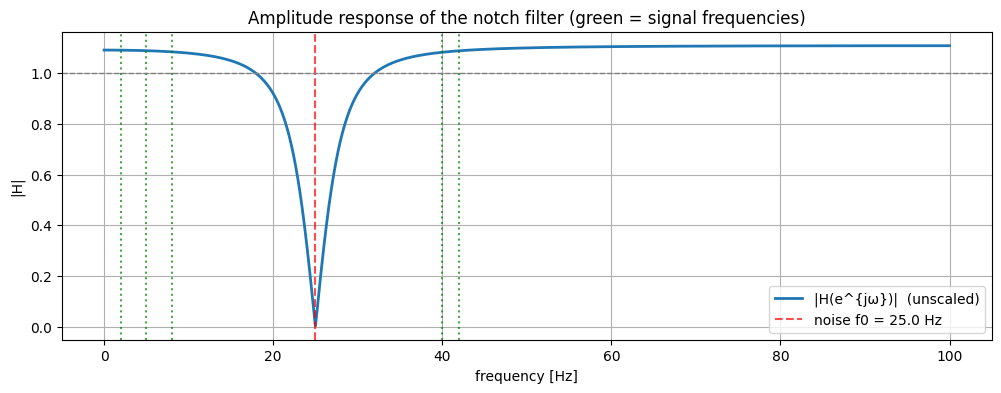

|H| at   0.0 Hz = 1.0904
|H| at   2.0 Hz = 1.0901
|H| at   5.0 Hz = 1.0880
|H| at   8.0 Hz = 1.0835
|H| at  25.0 Hz = 0.0000
|H| at  40.0 Hz = 1.0818
|H| at  42.0 Hz = 1.0876
|H| at 100.0 Hz = 1.1075


In [4]:
# --- Frequency grid: 0 ... fs/2 (fine resolution, independent of the DFT bins) ---
f_axis = np.linspace(0, fs/2, 2000)
w      = 2 * np.pi * f_axis / fs
z      = np.exp(1j * w)                      # points on the unit circle

# --- H(z) in product (factored) form ---
def H_of_z(z):
    num = np.ones_like(z)
    den = np.ones_like(z)
    for zk in zeros: num *= (z - zk)         # distances to zeros
    for pk in poles: den *= (z - pk)         # distances to poles
    return num / den

H = H_of_z(z)
H_mag = np.abs(H)

# --- Plot ---
plt.figure(figsize=(12, 4))
plt.plot(f_axis, H_mag, linewidth=2, label="|H(e^{jω})|  (unscaled)")
for fm in [2, 5, 8, 40, 42]:
    plt.axvline(fm, color="green", ls=":", alpha=0.7)
plt.axvline(f0, color="red", ls="--", alpha=0.7, label=f"noise f0 = {f0} Hz")
plt.axhline(1, color="gray", ls="--", lw=1)
plt.xlabel("frequency [Hz]"); plt.ylabel("|H|")
plt.title("Amplitude response of the notch filter (green = signal frequencies)")
plt.legend(); plt.grid(True); plt.show()

# --- Gain at the frequencies that matter ---
for fm in [0, 2, 5, 8, 25, 40, 42, 100]:
    print(f"|H| at {fm:5.1f} Hz = {abs(H_of_z(np.exp(1j*2*np.pi*fm/fs))):.4f}")

## Scale the filter so the passband gain is about 1

K = 0.91707


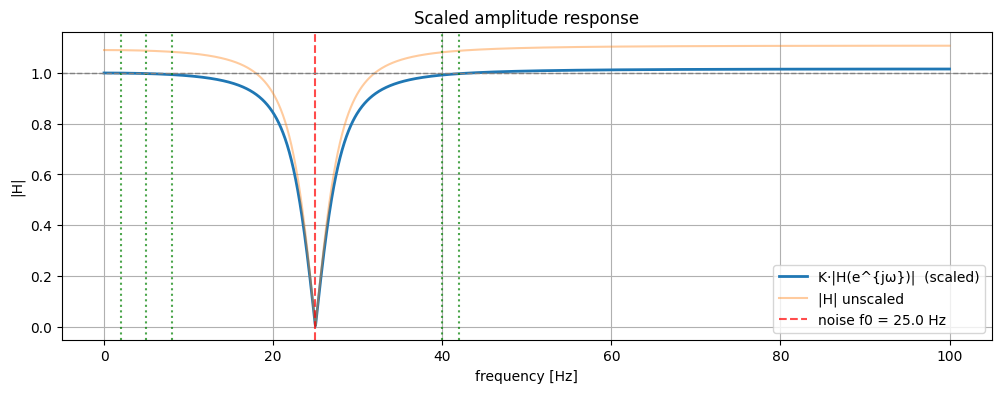

K·|H| at   0.0 Hz = 1.0000
K·|H| at   2.0 Hz = 0.9997
K·|H| at   5.0 Hz = 0.9978
K·|H| at   8.0 Hz = 0.9936
K·|H| at  25.0 Hz = 0.0000
K·|H| at  40.0 Hz = 0.9921
K·|H| at  42.0 Hz = 0.9974
K·|H| at 100.0 Hz = 1.0157


In [5]:
# --- Gain constant: normalize |H| to 1 at DC (z = 1) ---
K = 1 / np.abs(H_of_z(np.array([1.0+0j])))[0]
print(f"K = {K:.5f}")

H_scaled_mag = K * H_mag

# --- Plot scaled response ---
plt.figure(figsize=(12, 4))
plt.plot(f_axis, H_scaled_mag, linewidth=2, label="K·|H(e^{jω})|  (scaled)")
plt.plot(f_axis, H_mag, alpha=0.4, label="|H| unscaled")
for fm in [2, 5, 8, 40, 42]:
    plt.axvline(fm, color="green", ls=":", alpha=0.7)
plt.axvline(f0, color="red", ls="--", alpha=0.7, label=f"noise f0 = {f0} Hz")
plt.axhline(1, color="gray", ls="--", lw=1)
plt.xlabel("frequency [Hz]"); plt.ylabel("|H|")
plt.title("Scaled amplitude response")
plt.legend(); plt.grid(True); plt.show()

# --- Check the gain where it matters ---
for fm in [0, 2, 5, 8, 25, 40, 42, 100]:
    g = K * abs(H_of_z(np.exp(1j*2*np.pi*fm/fs)))
    print(f"K·|H| at {fm:5.1f} Hz = {g:.4f}")

# Expand the transfer function to get the z-transform coefficients

In [6]:
# --- Coefficients by hand (from the expansion above) ---
c = np.cos(theta0)

b = K * np.array([1.0, -2*c, 1.0])        # numerator   (zeros, scaled by K)
a =     np.array([1.0, -2*r*c, r**2])     # denominator (poles)

print("b =", np.round(b, 5))
print("a =", np.round(a, 5))

# --- Cross-check: let numpy multiply out the factors ---
b_check = K * np.real(np.poly(zeros))
a_check =     np.real(np.poly(poles))
print("Matches np.poly:", np.allclose(b, b_check) and np.allclose(a, a_check))

# --- Check: evaluating the polynomial form gives the same response as before ---
zi = np.exp(-1j * w)                      # z^-1 on the unit circle
H_poly = (b[0] + b[1]*zi + b[2]*zi**2) / (a[0] + a[1]*zi + a[2]*zi**2)
print("Same |H| as scaled factored form:", np.allclose(np.abs(H_poly), H_scaled_mag))

b = [ 0.91707 -1.29693  0.91707]
a = [ 1.      -1.27279  0.81   ]
Matches np.poly: True
Same |H| as scaled factored form: True


# Difference equation and filtering the signal

Matches scipy lfilter: True


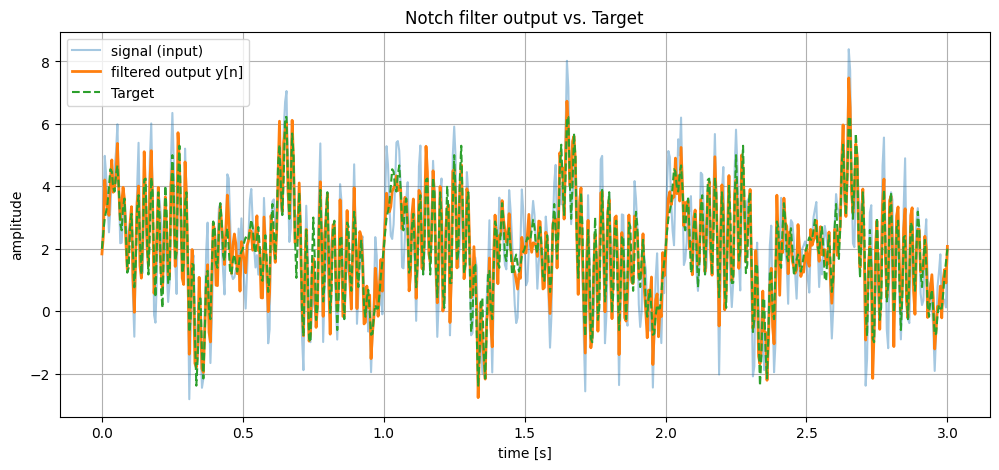

In [7]:
# --- Apply the difference equation sample by sample ---
y = np.zeros(N)
for i in range(N):
    y[i] = b[0]*x[i]
    if i >= 1: y[i] += b[1]*x[i-1] - a[1]*y[i-1]
    if i >= 2: y[i] += b[2]*x[i-2] - a[2]*y[i-2]
# (samples before n = 0 are taken as zero: x[-1] = x[-2] = y[-1] = y[-2] = 0)

# --- Cross-check with scipy's implementation of the same equation ---
from scipy.signal import lfilter
print("Matches scipy lfilter:", np.allclose(y, lfilter(b, a, x)))

# --- Plot: input, output, target ---
plt.figure(figsize=(12, 5))
plt.plot(t, x, alpha=0.4, label="signal (input)")
plt.plot(t, y, linewidth=2, label="filtered output y[n]")
plt.plot(t, target, "--", linewidth=1.5, label="Target")
plt.xlabel("time [s]"); plt.ylabel("amplitude")
plt.title("Notch filter output vs. Target")
plt.legend(); plt.grid(True); plt.show()

# Evaluate the result: the shift, the error, and the spectrum

 f [Hz]   |H|     phase [deg]   phase delay [samples]   [ms]
     2   1.000       -1.28           0.36              1.78
     5   0.998       -3.30           0.37              1.84
     8   0.994       -5.62           0.39              1.95
    40   0.992       14.21          -0.20             -0.99
    42   0.997       12.61          -0.17             -0.83

RMS(signal - Target) = 1.027
RMS(output - Target) = 0.544
   of which: noise passed through   = 0.498
             distortion of Target   = 0.245


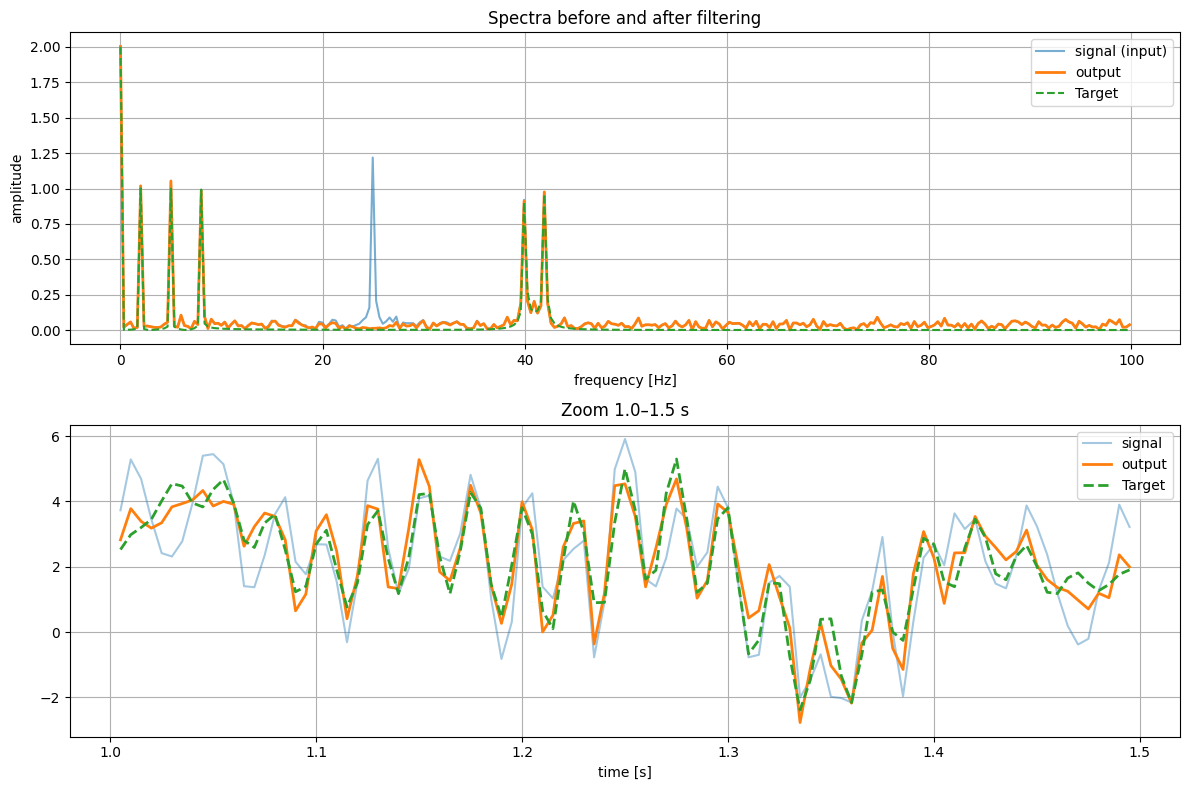


Amplitude at 25 Hz:  input 1.219  ->  output 0.013   (Target 0.002)


In [8]:
from scipy.signal import freqz, group_delay

skip = 60                         # ignore the start-up transient (~0.3 s)
f_sig = np.array([2, 5, 8, 40, 42])
w_sig = 2*np.pi*f_sig/fs

# --- 1. Phase and delay at the signal frequencies ---
_, h_sig  = freqz(b, a, worN=w_sig)
_, gd_sig = group_delay((b, a), w=w_sig)
phase     = np.angle(h_sig)
phase_dly = -phase / w_sig        # phase delay in samples

print(" f [Hz]   |H|     phase [deg]   phase delay [samples]   [ms]")
for fm, hm, ph, pd_ in zip(f_sig, np.abs(h_sig), np.degrees(phase), phase_dly):
    print(f"{fm:6.0f}  {hm:6.3f}   {ph:9.2f}      {pd_:9.2f}            {pd_*Ts*1e3:6.2f}")

# --- 2. RMS error vs. Target, before and after filtering ---
rms = lambda v: np.sqrt(np.mean(v[skip:]**2))
print(f"\nRMS(signal - Target) = {rms(x - target):.3f}")
print(f"RMS(output - Target) = {rms(y - target):.3f}")

# Split the remaining error into its two causes
noise_passed = lfilter(b, a, x - target)     # noise that got through the filter
distortion   = lfilter(b, a, target) - target  # what the filter does to the clean signal
print(f"   of which: noise passed through   = {rms(noise_passed):.3f}")
print(f"             distortion of Target   = {rms(distortion):.3f}")

# --- 3. Spectra: input vs. output vs. Target ---
Ay = amp_spectrum(np.fft.fft(y))
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
ax[0].plot(f, Ax, label="signal (input)", alpha=0.6)
ax[0].plot(f, Ay, label="output", linewidth=2)
ax[0].plot(f, At, "--", label="Target")
ax[0].set_xlabel("frequency [Hz]"); ax[0].set_ylabel("amplitude")
ax[0].set_title("Spectra before and after filtering"); ax[0].legend(); ax[0].grid(True)

# --- 4. Zoomed time-domain comparison (after the transient) ---
zoom = (t > 1.0) & (t < 1.5)
ax[1].plot(t[zoom], x[zoom], alpha=0.4, label="signal")
ax[1].plot(t[zoom], y[zoom], linewidth=2, label="output")
ax[1].plot(t[zoom], target[zoom], "--", linewidth=2, label="Target")
ax[1].set_xlabel("time [s]"); ax[1].set_title("Zoom 1.0–1.5 s")
ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

k25 = np.argmin(np.abs(f - 25))
print(f"\nAmplitude at 25 Hz:  input {Ax[k25]:.3f}  ->  output {Ay[k25]:.3f}   (Target {At[k25]:.3f})")

# Comparing filters

In [9]:
from scipy import signal

f_sig  = np.array([2, 5, 8, 40, 42])      # frequencies to keep
skip   = 100                              # ignore first 0.5 s (longer transients for higher orders)
rms    = lambda v: np.sqrt(np.mean(v[skip:]**2))

filters = {}                              # stores every filter we design

def evaluate(name, sos):
    """Filter the data with an SOS filter and store the key metrics."""
    y      = signal.sosfilt(sos, x)
    _, h   = signal.sosfreqz(sos, worN=2*np.pi*np.r_[f_sig, f0]/fs)
    z, p, k = signal.sos2zpk(sos)

    res = dict(
        sos=sos, y=y, zeros=z, poles=p,
        order=len(p),
        gain_sig=np.abs(h[:-1]),                     # |H| at the signal frequencies
        phase_sig=np.degrees(np.angle(h[:-1])),      # phase at the signal frequencies
        gain_f0=np.abs(h[-1]),                       # |H| at 25 Hz
        rms_total=rms(y - target),
        rms_noise=rms(signal.sosfilt(sos, x - target)),   # noise that got through
        rms_dist=rms(signal.sosfilt(sos, target) - target), # distortion of the clean signal
        max_pole_r=np.max(np.abs(p)),
    )
    filters[name] = res

    print(f"=== {name} ===  order = {res['order']},  max |pole| = {res['max_pole_r']:.3f}")
    print("  f [Hz]   :", "  ".join(f"{v:7.0f}" for v in f_sig), "     25")
    print("  |H|      :", "  ".join(f"{v:7.3f}" for v in res['gain_sig']), f"  {res['gain_f0']:.4f}")
    print("  phase [°]:", "  ".join(f"{v:7.1f}" for v in res['phase_sig']))
    print(f"  RMS error vs Target = {res['rms_total']:.3f}   "
          f"(noise passed {res['rms_noise']:.3f}, distortion {res['rms_dist']:.3f})")
    return res

# --- Register our hand-designed notch as the reference ---
sos_notch = signal.tf2sos(b, a)
evaluate("Pole-zero notch (ours)", sos_notch);

=== Pole-zero notch (ours) ===  order = 2,  max |pole| = 0.900
  f [Hz]   :       2        5        8       40       42      25
  |H|      :   1.000    0.998    0.994    0.992    0.997   0.0000
  phase [°]:    -1.3     -3.3     -5.6     14.2     12.6
  RMS error vs Target = 0.544   (noise passed 0.499, distortion 0.247)


## Butterworth band-stop

b = [ 0.80059 -2.29264  3.24254 -2.29264  0.80059]
a = [ 1.      -2.54941  3.20237 -2.03588  0.64135] 

=== Butterworth band-stop (order 2, 20–30 Hz) ===  order = 4,  max |pole| = 0.906
  f [Hz]   :       2        5        8       40       42      25
  |H|      :   1.000    1.000    1.000    0.991    0.994   0.0062
  phase [°]:    -2.9     -7.4    -12.7     31.2     27.5
  RMS error vs Target = 0.703   (noise passed 0.486, distortion 0.538)


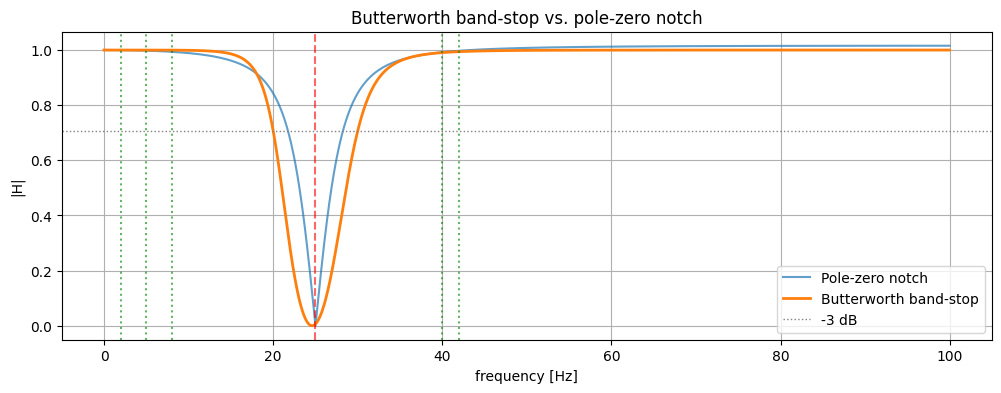

In [10]:
# --- Design: order-2 Butterworth band-stop, -3 dB edges at 20 and 30 Hz ---
bw_order = 2
bw_edges = [20, 30]
sos_bw = signal.butter(bw_order, bw_edges, btype="bandstop", fs=fs, output="sos")

# Equivalent transfer-function coefficients (for the report)
b_bw, a_bw = signal.sos2tf(sos_bw)
print("b =", np.round(b_bw, 5))
print("a =", np.round(a_bw, 5), "\n")

res_bw = evaluate("Butterworth band-stop (order 2, 20–30 Hz)", sos_bw)

# --- Magnitude response compared with the notch ---
w_ax, h_bw = signal.sosfreqz(sos_bw,   worN=4096, fs=fs)
_,    h_nt = signal.sosfreqz(sos_notch, worN=4096, fs=fs)

plt.figure(figsize=(12, 4))
plt.plot(w_ax, np.abs(h_nt), label="Pole-zero notch", alpha=0.7)
plt.plot(w_ax, np.abs(h_bw), linewidth=2, label="Butterworth band-stop")
for fm in f_sig: plt.axvline(fm, color="green", ls=":", alpha=0.6)
plt.axvline(f0, color="red", ls="--", alpha=0.6)
plt.axhline(1/np.sqrt(2), color="gray", ls=":", lw=1, label="-3 dB")
plt.xlabel("frequency [Hz]"); plt.ylabel("|H|")
plt.title("Butterworth band-stop vs. pole-zero notch")
plt.legend(); plt.grid(True); plt.show()

## Chebyshev type II band-stop

b = [ 0.70131 -2.97539  6.3076  -7.92849  6.3076  -2.97539  0.70131]
a = [ 1.      -3.74636  7.00115 -7.8021   5.52486 -2.33082  0.49181] 

=== Chebyshev II band-stop (order 3, 40 dB, 23–27 Hz) ===  order = 6,  max |pole| = 0.930
  f [Hz]   :       2        5        8       40       42      25
  |H|      :   1.000    1.000    1.000    0.996    0.998   0.0009
  phase [°]:    -4.4    -11.5    -19.7     50.9     44.6
  RMS error vs Target = 0.958   (noise passed 0.481, distortion 0.858)

Zero frequencies [Hz]: [23.25 24.94 26.72]


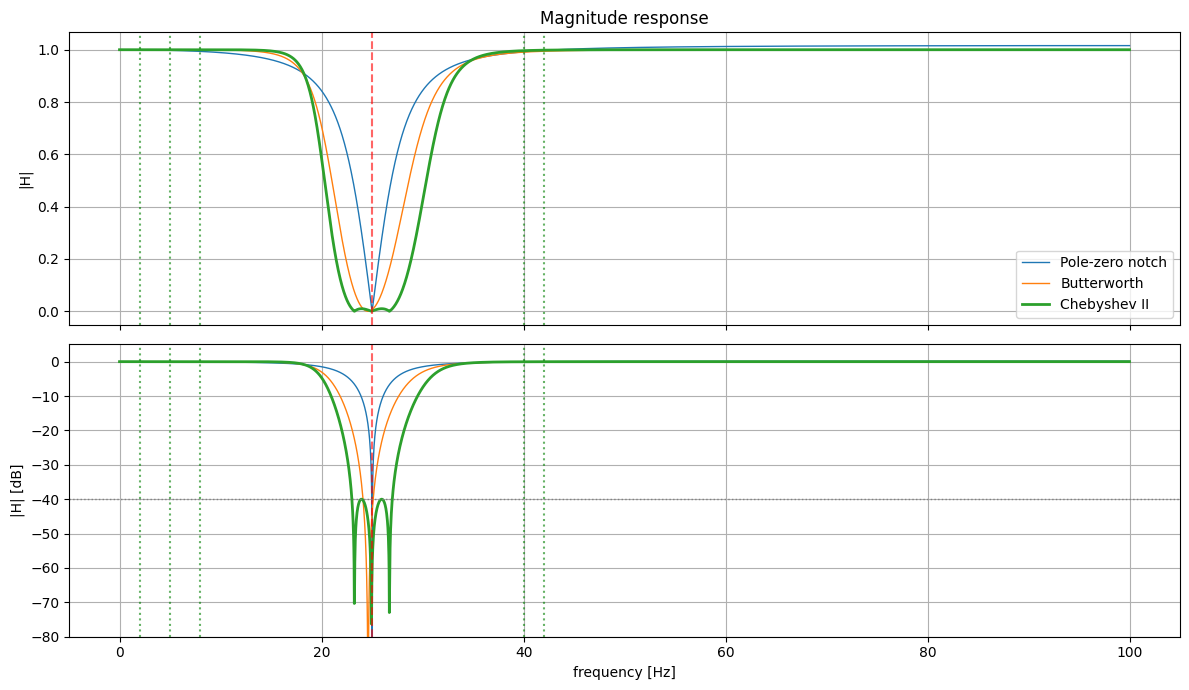

In [12]:
# --- Design: order-3 Chebyshev II band-stop, Rs = 40 dB, stopband edges 23–27 Hz ---
ch_order = 3
ch_rs    = 40            # minimum stopband attenuation [dB]
ch_edges = [23, 27]      # NOTE: for cheby2 these are the STOPBAND edges, not -3 dB points
sos_ch = signal.cheby2(ch_order, ch_rs, ch_edges, btype="bandstop", fs=fs, output="sos")

b_ch, a_ch = signal.sos2tf(sos_ch)
print("b =", np.round(b_ch, 5))
print("a =", np.round(a_ch, 5), "\n")

res_ch = evaluate("Chebyshev II band-stop (order 3, 40 dB, 23–27 Hz)", sos_ch)

# Where did the zeros land? (frequency of each zero on the unit circle)
zf = np.angle(res_ch["zeros"]) * fs / (2*np.pi)
print("\nZero frequencies [Hz]:", np.round(np.sort(zf[zf > 0]), 2))

# --- Magnitude: linear and in dB, compared with the other two ---
w_ax, h_ch = signal.sosfreqz(sos_ch, worN=4096, fs=fs)

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for hh, lab, lw in [(h_nt, "Pole-zero notch", 1), (h_bw, "Butterworth", 1), (h_ch, "Chebyshev II", 2)]:
    ax[0].plot(w_ax, np.abs(hh), lw=lw, label=lab)
    ax[1].plot(w_ax, 20*np.log10(np.abs(hh) + 1e-12), lw=lw, label=lab)
for a_ in ax:
    for fm in f_sig: a_.axvline(fm, color="green", ls=":", alpha=0.6)
    a_.axvline(f0, color="red", ls="--", alpha=0.6); a_.grid(True)
ax[0].set_ylabel("|H|"); ax[0].legend(); ax[0].set_title("Magnitude response")
ax[1].set_ylabel("|H| [dB]"); ax[1].set_ylim(-80, 5); ax[1].set_xlabel("frequency [Hz]")
ax[1].axhline(-ch_rs, color="gray", ls=":", lw=1)
plt.tight_layout(); plt.show()

# Side-by-side filters comparison

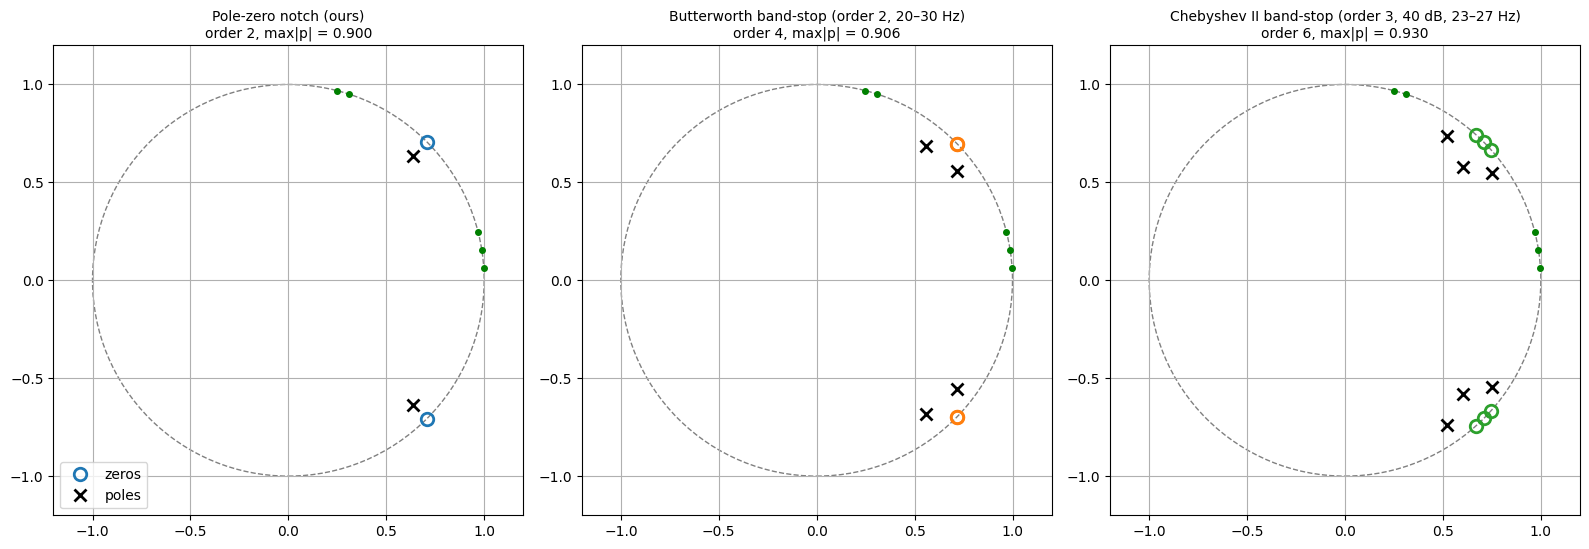

C:\Users\shahriar\AppData\Local\Temp\ipykernel_3252\3324131337.py:24: UserWarning: The filter's denominator is extremely small at frequencies [0.785], around which a singularity may be present
  _, gd    = signal.group_delay(signal.sos2tf(sos), w=w_ax, fs=fs)


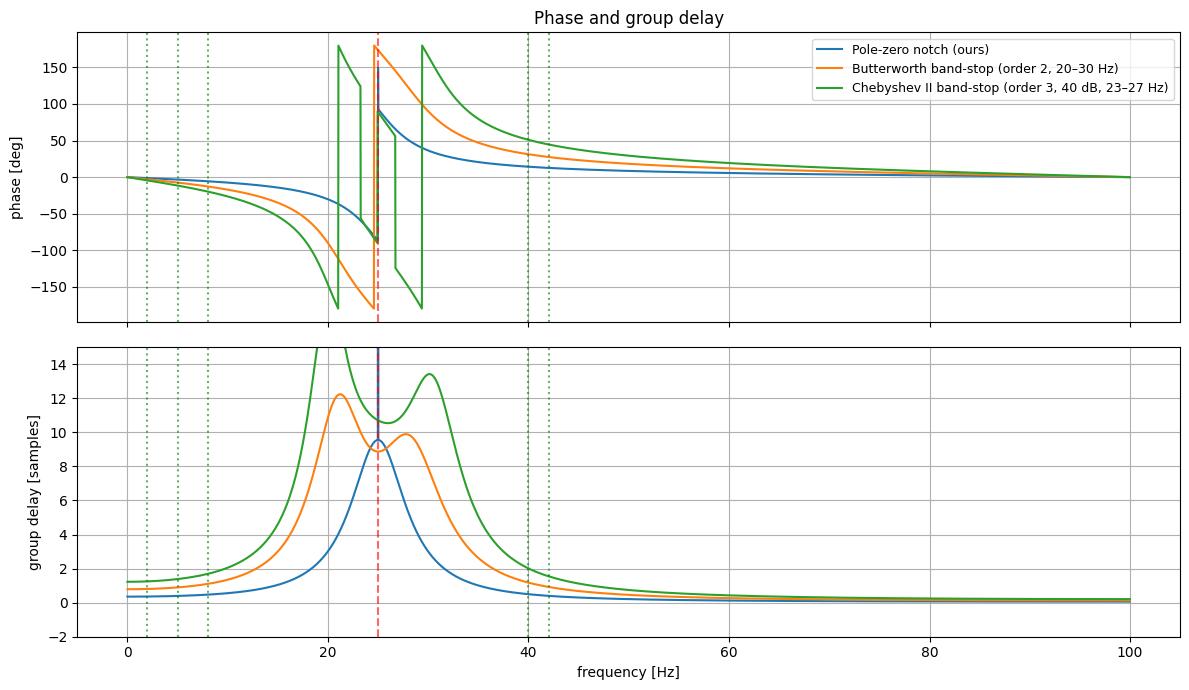

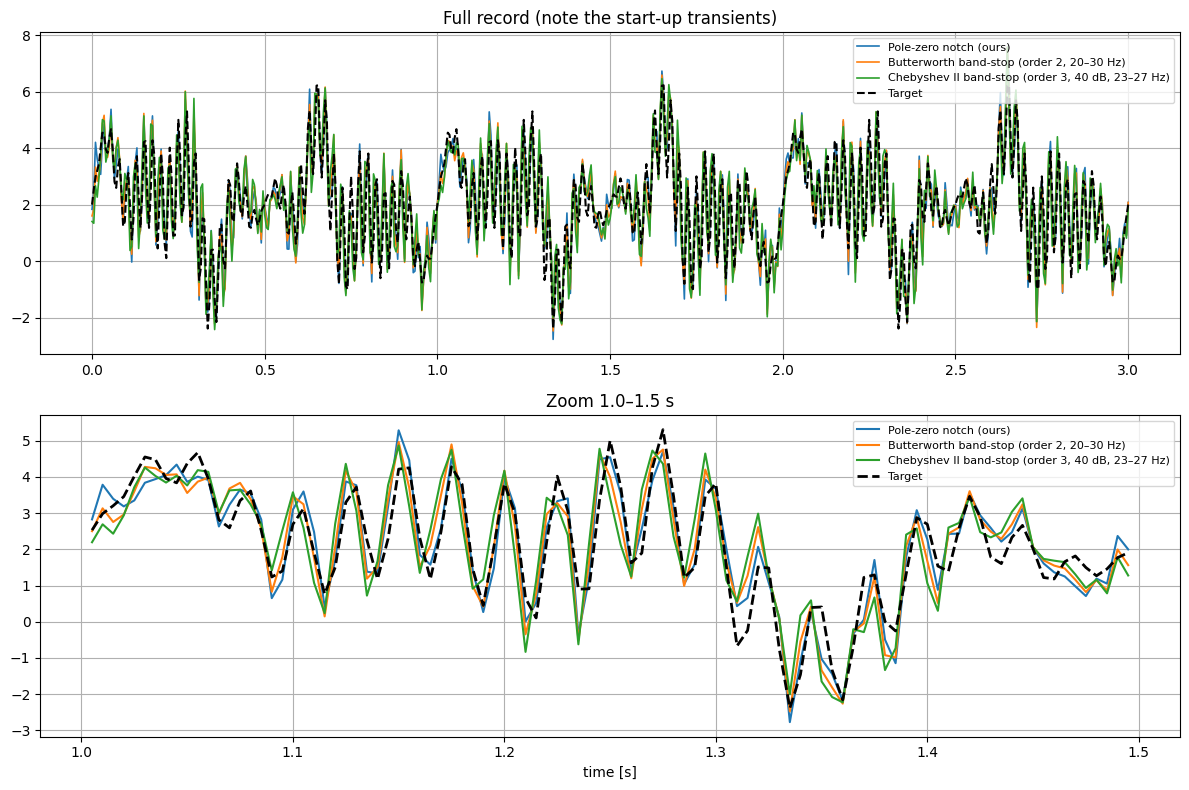

Reference: RMS(signal - Target) = 1.032



filter,Pole-zero notch (ours),"Butterworth band-stop (order 2, 20–30 Hz)","Chebyshev II band-stop (order 3, 40 dB, 23–27 Hz)"
order (poles),2.000,4.0000,6.0000
|H| @25 Hz,0.000,0.0062,0.0009
min |H| at signal f,0.992,0.9910,0.9960
phase @8 Hz [°],-5.600,-12.7000,-19.7000
phase @40 Hz [°],14.200,31.2000,50.9000
settling [s],0.220,0.1900,0.2750
RMS noise passed,0.499,0.4860,0.4810
RMS distortion,0.247,0.5380,0.8580
RMS total,0.544,0.7030,0.9580


In [13]:
names  = list(filters.keys())
colors = ["C0", "C1", "C2"]

# ---------- 1. Pole-zero maps ----------
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
for a_, nm, col in zip(ax, names, colors):
    r_ = filters[nm]
    a_.add_patch(plt.Circle((0, 0), 1, fill=False, ls="--", color="gray"))
    a_.plot(r_["zeros"].real, r_["zeros"].imag, "o", ms=9, mfc="none", mew=2, color=col, label="zeros")
    a_.plot(r_["poles"].real, r_["poles"].imag, "x", ms=9, mew=2, color="k", label="poles")
    for fm in f_sig:
        ang = 2*np.pi*fm/fs
        a_.plot(np.cos(ang), np.sin(ang), ".", color="green", ms=8)
    a_.set_aspect("equal"); a_.set_xlim(-1.2, 1.2); a_.set_ylim(-1.2, 1.2); a_.grid(True)
    a_.set_title(f"{nm}\norder {r_['order']}, max|p| = {r_['max_pole_r']:.3f}", fontsize=10)
ax[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

# ---------- 2. Phase and group delay ----------
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for nm, col in zip(names, colors):
    sos = filters[nm]["sos"]
    w_ax, hh = signal.sosfreqz(sos, worN=4096, fs=fs)
    _, gd    = signal.group_delay(signal.sos2tf(sos), w=w_ax, fs=fs)
    ax[0].plot(w_ax, np.degrees(np.angle(hh)), color=col, label=nm)
    ax[1].plot(w_ax, gd, color=col, label=nm)
for a_ in ax:
    for fm in f_sig: a_.axvline(fm, color="green", ls=":", alpha=0.6)
    a_.axvline(f0, color="red", ls="--", alpha=0.6); a_.grid(True)
ax[0].set_ylabel("phase [deg]"); ax[0].legend(fontsize=9); ax[0].set_title("Phase and group delay")
ax[1].set_ylabel("group delay [samples]"); ax[1].set_ylim(-2, 15); ax[1].set_xlabel("frequency [Hz]")
plt.tight_layout(); plt.show()

# ---------- 3. Time-domain outputs ----------
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
for nm, col in zip(names, colors):
    ax[0].plot(t, filters[nm]["y"], color=col, lw=1.2, label=nm)
ax[0].plot(t, target, "k--", lw=1.5, label="Target")
ax[0].set_title("Full record (note the start-up transients)")
zoom = (t > 1.0) & (t < 1.5)
for nm, col in zip(names, colors):
    ax[1].plot(t[zoom], filters[nm]["y"][zoom], color=col, lw=1.5, label=nm)
ax[1].plot(t[zoom], target[zoom], "k--", lw=2, label="Target")
ax[1].set_title("Zoom 1.0–1.5 s"); ax[1].set_xlabel("time [s]")
for a_ in ax: a_.grid(True); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---------- 4. Settling time (impulse response decays below 1% of its peak) ----------
def settling_samples(sos, thr=0.01):
    imp = np.zeros(2000); imp[0] = 1
    h   = np.abs(signal.sosfilt(sos, imp))[1:]     # skip the direct term h[0]
    return np.where(h > thr*h.max())[0][-1] + 1

# ---------- 5. Summary table ----------
rows = []
for nm in names:
    r_ = filters[nm]
    rows.append({
        "filter": nm,
        "order (poles)": r_["order"],
        "|H| @25 Hz": round(r_["gain_f0"], 4),
        "min |H| at signal f": round(r_["gain_sig"].min(), 3),
        "phase @8 Hz [°]": round(r_["phase_sig"][2], 1),
        "phase @40 Hz [°]": round(r_["phase_sig"][3], 1),
        "settling [s]": round(settling_samples(r_["sos"]) / fs, 3),
        "RMS noise passed": round(r_["rms_noise"], 3),
        "RMS distortion": round(r_["rms_dist"], 3),
        "RMS total": round(r_["rms_total"], 3),
    })
summary = pd.DataFrame(rows).set_index("filter")
print(f"Reference: RMS(signal - Target) = {rms(x - target):.3f}\n")
summary.T

# Zero-phase filtering. Was the difference phase or magnitude?

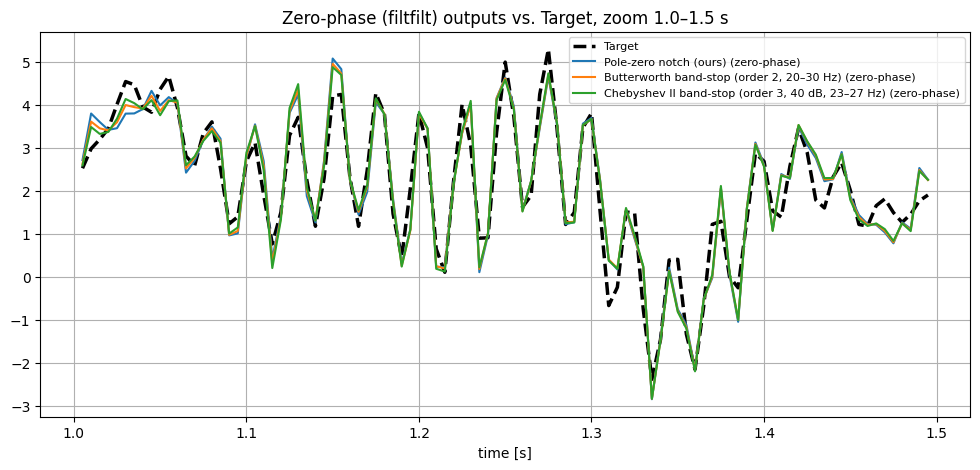

Reference: RMS(signal - Target) = 1.028



filter,Pole-zero notch (ours),"Butterworth band-stop (order 2, 20–30 Hz)","Chebyshev II band-stop (order 3, 40 dB, 23–27 Hz)"
causal: noise,0.504,0.491,0.486
causal: distortion,0.247,0.538,0.858
causal: total,0.554,0.714,0.966
zero-phase: noise,0.498,0.482,0.479
zero-phase: distortion,0.015,0.015,0.006
zero-phase: total,0.498,0.483,0.480


In [14]:
# Trim BOTH ends now: filtfilt has transients at the start and at the end
rms2 = lambda v: np.sqrt(np.mean(v[skip:N-skip]**2))

rows = []
fig, ax = plt.subplots(figsize=(12, 5))
zoom = (t > 1.0) & (t < 1.5)
ax.plot(t[zoom], target[zoom], "k--", lw=2.5, label="Target")

for nm, col in zip(names, colors):
    sos = filters[nm]["sos"]
    causal = lambda v: signal.sosfilt(sos, v)
    zphase = lambda v: signal.sosfiltfilt(sos, v)

    y_zp = zphase(x)
    filters[nm]["y_zp"] = y_zp
    ax.plot(t[zoom], y_zp[zoom], color=col, lw=1.5, label=f"{nm} (zero-phase)")

    rows.append({
        "filter": nm,
        "causal: noise":      round(rms2(causal(x - target)), 3),
        "causal: distortion": round(rms2(causal(target) - target), 3),
        "causal: total":      round(rms2(causal(x) - target), 3),
        "zero-phase: noise":      round(rms2(zphase(x - target)), 3),
        "zero-phase: distortion": round(rms2(zphase(target) - target), 3),
        "zero-phase: total":      round(rms2(y_zp - target), 3),
    })

ax.set_title("Zero-phase (filtfilt) outputs vs. Target, zoom 1.0–1.5 s")
ax.set_xlabel("time [s]"); ax.grid(True); ax.legend(fontsize=8)
plt.show()

print(f"Reference: RMS(signal - Target) = {rms2(x - target):.3f}\n")
pd.DataFrame(rows).set_index("filter").T

# Spectra before and after filtering, for all filters

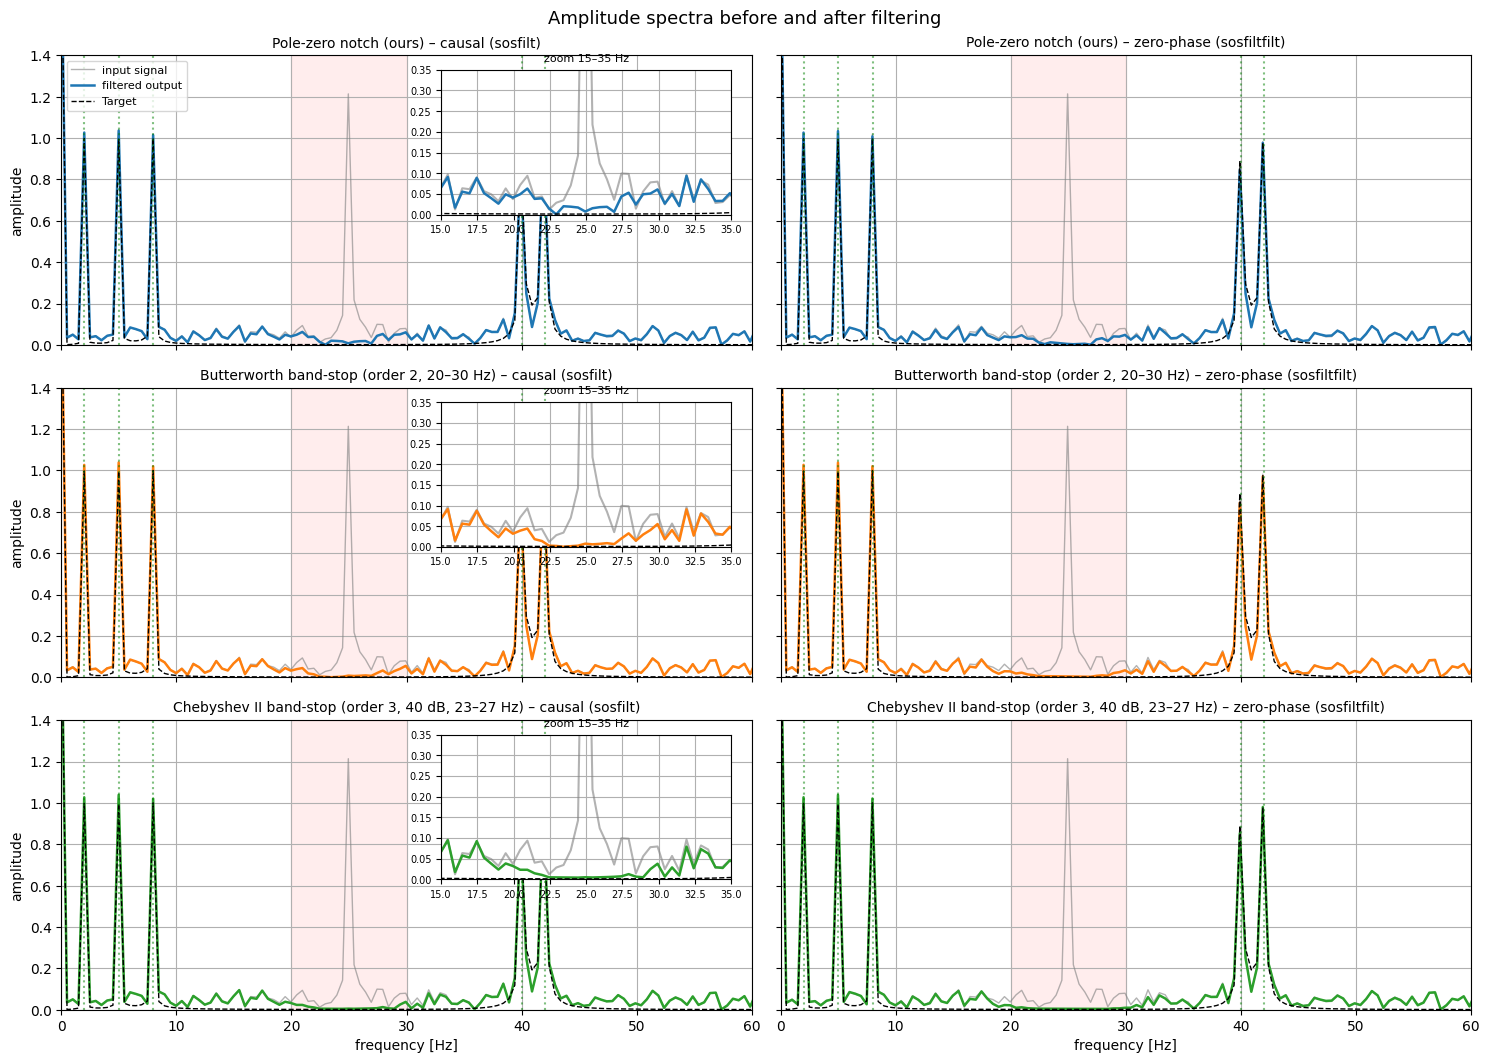

In [15]:
# Common analysis window: drop transients at both ends (filtfilt needs the end trimmed too)
win   = slice(skip, N - skip)
Nw    = N - 2*skip
f_w   = np.arange(Nw//2 + 1) * fs / Nw

def spec(v):
    A = np.abs(np.fft.rfft(v[win])) / Nw
    A[1:] *= 2
    return A

A_in, A_tg = spec(x), spec(target)

fig, ax = plt.subplots(len(names), 2, figsize=(15, 3.6*len(names)), sharex=True, sharey=True)
for i, (nm, col) in enumerate(zip(names, colors)):
    for j, (key, mode) in enumerate([("y", "causal (sosfilt)"), ("y_zp", "zero-phase (sosfiltfilt)")]):
        a_ = ax[i, j]
        a_.plot(f_w, A_in, color="gray", alpha=0.6, lw=1, label="input signal")
        a_.plot(f_w, spec(filters[nm][key]), color=col, lw=1.8, label="filtered output")
        a_.plot(f_w, A_tg, "k--", lw=1, label="Target")
        a_.axvspan(20, 30, color="red", alpha=0.07)            # noise region
        for fm in f_sig: a_.axvline(fm, color="green", ls=":", alpha=0.5)
        a_.set_title(f"{nm} – {mode}", fontsize=10)
        a_.grid(True)
        if j == 0: a_.set_ylabel("amplitude")
        if i == len(names)-1: a_.set_xlabel("frequency [Hz]")

    # inset: zoom on the noise region for the causal panel
    ins = ax[i, 0].inset_axes([0.55, 0.45, 0.42, 0.5])
    ins.plot(f_w, A_in, color="gray", alpha=0.6)
    ins.plot(f_w, spec(filters[nm]["y"]), color=col, lw=1.8)
    ins.plot(f_w, A_tg, "k--", lw=1)
    ins.set_xlim(15, 35); ins.set_ylim(0, 0.35); ins.grid(True)
    ins.set_title("zoom 15–35 Hz", fontsize=8); ins.tick_params(labelsize=7)

ax[0, 0].legend(loc="upper left", fontsize=8)
ax[0, 0].set_xlim(0, 60)
ax[0, 0].set_ylim(0, 1.4)                    # clip the DC bar (~2) so the tones are readable
fig.suptitle("Amplitude spectra before and after filtering", fontsize=13)
plt.tight_layout(); plt.show()